In [1]:
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import torch
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from torchvision.models import resnet18, ResNet18_Weights
import time

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
])

# Download and load the EuroSAT dataset (RGB version)
dataset = datasets.EuroSAT(
    root="../data/raw/EuroSAT",
    transform=transform,
    download=True,
)

In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [4]:
generator = torch.Generator().manual_seed(0)
train_set, val_set, test_set = torch.utils.data.random_split(
    dataset, [.8, .1, .1], generator = generator)


In [5]:
# create data loader for training data
stats_dataloader = DataLoader(train_set, batch_size = 512, shuffle = False)

We want to transform the data by normalising it. To this end, we first compute its mean and standard deviation

In [6]:
s = torch.zeros(3, dtype=torch.float64)
s2 = torch.zeros(3, dtype=torch.float64)
N = 0
for batch, label in stats_dataloader:
    batch = batch.double()
    s += batch.sum(dim = (0, 2, 3))    # batch has shape [512, 3, 64, 64] : [images, channels, height, width]
    s2 += (batch ** 2).sum(dim = (0, 2, 3))
    N += batch.shape[0] * batch.shape[2] * batch.shape[3]

mean = s / N
stdv = (s2 / N - mean ** 2) ** .5

print("mean:", mean)
print("stdv:", stdv)

mean: tensor([0.3433, 0.3797, 0.4075], dtype=torch.float64)
stdv: tensor([0.2017, 0.1364, 0.1152], dtype=torch.float64)


Define the normalisation transform for the dataset. This will not change the images themselves, but rather transform them whenever they are requested from the dataset.

In [7]:
dataset.transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean.tolist(), stdv.tolist())
])

In [8]:
loader_gen = torch.Generator().manual_seed(0)
train_dataloader = DataLoader(train_set, batch_size = 64, shuffle = True, generator = loader_gen)
val_dataloader = DataLoader(val_set, batch_size = 64, shuffle = False, generator = loader_gen)
test_dataloader = DataLoader(test_set, batch_size = 64, shuffle = False, generator = loader_gen)

Plot some images from the training set

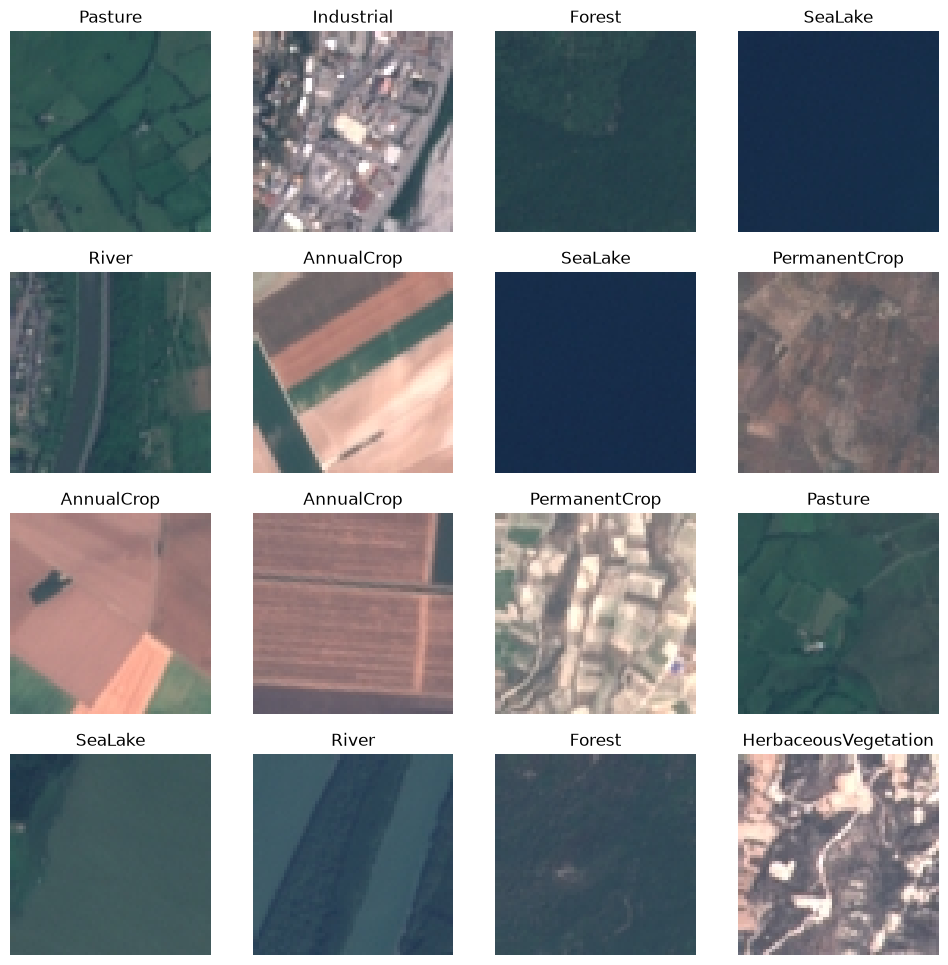

In [9]:
mean_t = mean.float().view(3, 1, 1)
std_t  = stdv.float().view(3, 1, 1)


figure = plt.figure(figsize=(12, 12))
cols, rows = 4, 4
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(train_set), size=(1,)).item()
    img, label = train_set[sample_idx]
    img = (img * std_t + mean_t).clamp(0, 1)

    # torch and matplotlib have different channel orders, so permute the image tensor
    img = img.permute(1, 2, 0)
    figure.add_subplot(rows, cols, i)
    plt.title(dataset.classes[label])
    plt.axis("off")
    plt.imshow(img)  

plt.show()

### Define the CNN model

CNNs are the standard tool for classifying images, as they keep pixel neighbourhoods and are able to learn patterns using shared filters, thus needing far fewer parameters than fully connected networks. For 64 × 64 pixel inputs such as EuroSAT ones, we implement a common small CNN consisting of three convolution blocks (Conv 3×3 → BatchNorm → ReLU → MaxPool) with 32 → 64 → 128 channels, followed by dropout (0.3) and a linear head. 


In [10]:
from torch import nn

def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size = 3, padding = 1, bias = False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2)
    )


class CNN(nn.Module):
    def __init__(self, n_classes = 10):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128 * 8 * 8, n_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


In [11]:
model = CNN().to(device)
tensor = torch.zeros(2, 3, 64, 64).to(device)
model(tensor).shape

torch.Size([2, 10])

Define training functions

In [12]:
def train_one_epoch(model, dataloader, loss_fn, optimizer, device):
    model.train()
    total_loss = 0.0
    Ncorrect = 0
    Ntotal = 0

    for X, y in dataloader:
        # move data to device
        X, y = X.to(device), y.to(device)

        # forward pass
        logits = model(X)

        # compute loss
        loss = loss_fn(logits, y)

        # backward pass
        optimizer.zero_grad()
        loss.backward()

        # update weights
        optimizer.step()

        # compute figures of merit
        total_loss += loss.item() * X.shape[0]
        Ncorrect += (logits.argmax(dim=1) == y).sum().item()
        Ntotal += X.shape[0]

    return total_loss / Ntotal, Ncorrect / Ntotal

def evaluate(model, dataloader, loss_fn, device):
    model.eval()
    total_loss = 0.0
    Ncorrect = 0
    Ntotal = 0

    with torch.no_grad():
        for X, y in dataloader:
            # move data to device
            X, y = X.to(device), y.to(device)
        
            # forward pass
            logits = model(X)
        
            # compute loss
            loss = loss_fn(logits, y)

            # compute figures of merit
            total_loss += loss.item() * X.shape[0]
            Ncorrect += (logits.argmax(dim=1) == y).sum().item()
            Ntotal += X.shape[0]

    return total_loss / Ntotal, Ncorrect / Ntotal


def fit(model, train_dataloader, val_dataloader, loss_fn, n_epochs, lr, device,
        cosine_schedule = True, ckpt_path = None, verbose = False):

    optimizer = torch.optim.Adam((p for p in model.parameters() if p.requires_grad), lr=lr)
    scheduler = (torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)
                 if cosine_schedule else None)

    metrics = []
    best_acc = 0.0
    for epoch in range(n_epochs):
        t_start = time.perf_counter()
        train_loss, train_acc = train_one_epoch(model, train_dataloader, loss_fn, optimizer, device)
        val_loss, val_acc = evaluate(model, val_dataloader, loss_fn, device)

        # read the lr from the optimizer: works with or without a scheduler
        current_lr = optimizer.param_groups[0]["lr"]
        if scheduler is not None:
            scheduler.step()

        metrics.append({"epoch": epoch,
                        "lr": current_lr,
                        "train_loss": train_loss,
                        "train_acc": train_acc,
                        "val_loss": val_loss,
                        "val_acc": val_acc,
                        "seconds": time.perf_counter() - t_start})

        # keep the weights of the best validation epoch
        if val_acc > best_acc:
            best_acc = val_acc
            if ckpt_path is not None:
                torch.save(model.state_dict(), ckpt_path)

        if verbose:
            print(f"{epoch:2d}:   lr {current_lr:.1e},   train {train_loss:.3f}/{train_acc:.3f},   validation {val_loss:.3f} / {val_acc:.3f}")

    return pd.DataFrame(metrics).set_index("epoch")

Test the model with a single batch

In [13]:
model = CNN().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 1e-3)

X, y = next(iter(train_dataloader))
X = X.to(device)
y = y.to(device)

model.train()
Nsteps = 100
for step in range(Nsteps):
    loss = loss_fn(model(X), y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if step % 10 == 0:
        print(step, loss.item())


0 2.407029628753662
10 0.17258292436599731
20 0.035209812223911285
30 0.008980006910860538
40 0.003312441986054182
50 0.0023710911627858877
60 0.0012858655536547303
70 0.0013480052584782243
80 0.0009208247065544128
90 0.0007437344756908715


### Train the model

Let us first try with a constant learning rate

In [14]:
torch.manual_seed(0)
model = CNN().to(device)

metrics_const = fit(model, train_dataloader, val_dataloader, loss_fn,
                    n_epochs = 15, lr = 1e-3, device = device,
                    cosine_schedule = False, verbose = True)

 0:   lr 1.0e-03,   train 0.963/0.681,   validation 0.746 / 0.757
 1:   lr 1.0e-03,   train 0.613/0.801,   validation 0.655 / 0.815
 2:   lr 1.0e-03,   train 0.482/0.840,   validation 0.612 / 0.819
 3:   lr 1.0e-03,   train 0.403/0.866,   validation 0.466 / 0.853
 4:   lr 1.0e-03,   train 0.346/0.883,   validation 0.405 / 0.869
 5:   lr 1.0e-03,   train 0.299/0.899,   validation 0.405 / 0.879
 6:   lr 1.0e-03,   train 0.270/0.908,   validation 0.405 / 0.878
 7:   lr 1.0e-03,   train 0.231/0.922,   validation 0.400 / 0.877
 8:   lr 1.0e-03,   train 0.212/0.925,   validation 0.307 / 0.899
 9:   lr 1.0e-03,   train 0.187/0.936,   validation 0.445 / 0.869
10:   lr 1.0e-03,   train 0.171/0.940,   validation 0.361 / 0.893
11:   lr 1.0e-03,   train 0.158/0.946,   validation 0.292 / 0.913
12:   lr 1.0e-03,   train 0.131/0.954,   validation 0.399 / 0.881
13:   lr 1.0e-03,   train 0.143/0.950,   validation 0.341 / 0.913
14:   lr 1.0e-03,   train 0.123/0.958,   validation 0.254 / 0.926


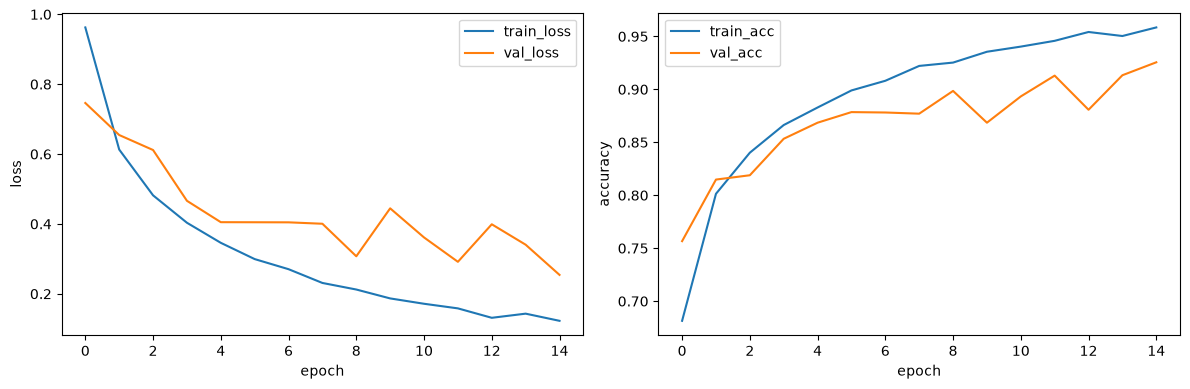

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
metrics_const[["train_loss", "val_loss"]].plot(ax=axes[0], ylabel="loss")
metrics_const[["train_acc", "val_acc"]].plot(ax=axes[1], ylabel="accuracy")
plt.tight_layout()
plt.show()

Validation bounces heavily, indicating that the constant learning rate is too large at the final epochs and the weights keep overshooting near the optimum. Picking the best epoch from such a noisy curve gives a rather optimistic estimate: let's try with a learning-rate schedule instead

In [16]:
torch.manual_seed(0)
model = CNN().to(device)

metrics_cos = fit(model, train_dataloader, val_dataloader, loss_fn,
                 n_epochs = 15, lr = 1e-3, device = device,
                 cosine_schedule = True,
                 ckpt_path = "../data/processed/eurosat_cnn_best.pt",
                 verbose = True)

 0:   lr 1.0e-03,   train 0.968/0.677,   validation 0.671 / 0.792
 1:   lr 9.9e-04,   train 0.587/0.805,   validation 0.533 / 0.837
 2:   lr 9.6e-04,   train 0.473/0.840,   validation 0.587 / 0.818
 3:   lr 9.0e-04,   train 0.398/0.865,   validation 0.421 / 0.863
 4:   lr 8.3e-04,   train 0.330/0.886,   validation 0.367 / 0.881
 5:   lr 7.5e-04,   train 0.287/0.899,   validation 0.358 / 0.882
 6:   lr 6.5e-04,   train 0.226/0.922,   validation 0.321 / 0.896
 7:   lr 5.5e-04,   train 0.196/0.930,   validation 0.305 / 0.896
 8:   lr 4.5e-04,   train 0.164/0.944,   validation 0.327 / 0.897
 9:   lr 3.5e-04,   train 0.137/0.953,   validation 0.267 / 0.911
10:   lr 2.5e-04,   train 0.115/0.961,   validation 0.220 / 0.925
11:   lr 1.7e-04,   train 0.098/0.968,   validation 0.227 / 0.923
12:   lr 9.5e-05,   train 0.085/0.973,   validation 0.209 / 0.931
13:   lr 4.3e-05,   train 0.076/0.976,   validation 0.198 / 0.933
14:   lr 1.1e-05,   train 0.071/0.977,   validation 0.202 / 0.929


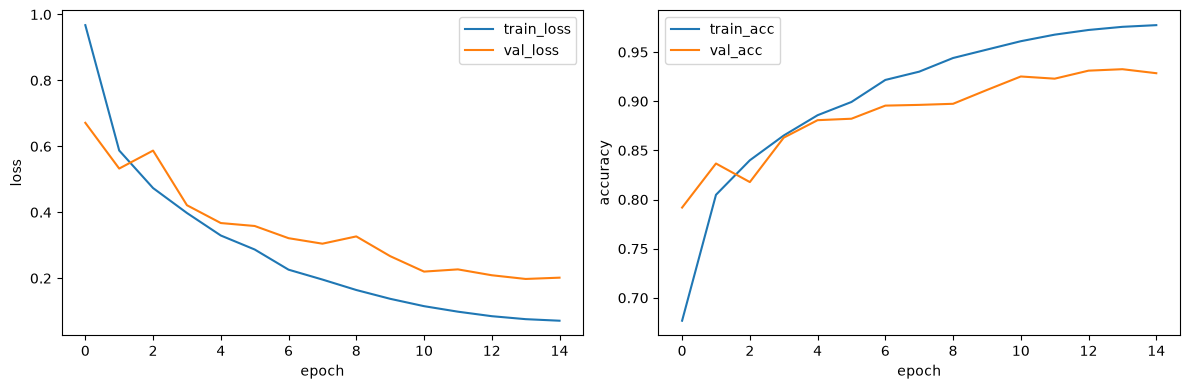

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
metrics_cos[["train_loss", "val_loss"]].plot(ax=axes[0], ylabel="loss")
metrics_cos[["train_acc", "val_acc"]].plot(ax=axes[1], ylabel="accuracy")
plt.tight_layout()
plt.show()


The validation curve settles as the learning rate drops, and the best epoch is the final one

### Test the model

In [18]:
# load the optimal model
path = "../data/processed/eurosat_cnn_best.pt"
model = CNN().to(device)
model.load_state_dict(torch.load(path, weights_only = True))

# evaluate it on the test set
test_loss, test_acc = evaluate(model, test_dataloader, loss_fn, device)

# compute the 95% confidence interval for the accuracy
std_error = np.sqrt(test_acc * (1 - test_acc) / len(test_dataloader.dataset))
ci = 1.96 * std_error

print("test loss:", np.round(test_loss, 3))
print("test accuracy:", np.round(test_acc, 3))
print("95% CI for test accuracy: [", np.round(test_acc - ci, 3), ",", np.round(test_acc + ci, 3), "]")


test loss: 0.179
test accuracy: 0.943
95% CI for test accuracy: [ 0.934 , 0.951 ]


The trained model obtains around a 94% accuracy on the test data. Let us break it down and look how it performs for each class, and compute the confusion matrix.

per class recall (correct / true count):
Highway                 0.853
PermanentCrop           0.916
River                   0.917
HerbaceousVegetation    0.929
AnnualCrop              0.937
Pasture                 0.961
Forest                  0.965
Industrial              0.970
SeaLake                 0.983
Residential             0.989
dtype: float64


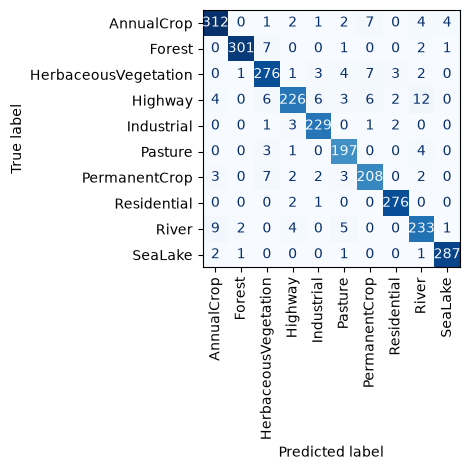

In [19]:
# collect predictions from the test set
model.eval()
y_true = []
y_pred = []
with torch.no_grad():
    for X, y in test_dataloader:
        logits = model (X.to(device))
        y_pred.append(logits.argmax(dim = 1).cpu())
        y_true.append(y)
y_true = torch.cat(y_true).numpy()
y_pred = torch.cat(y_pred).numpy()

# compute confusion matrix and per-class recall
cm = confusion_matrix(y_true, y_pred)
per_class_acc = cm.diagonal() / cm.sum(axis = 1)



print("per class recall (correct / true count):")
print(pd.Series(per_class_acc, index=dataset.classes).sort_values().round(3))

disp = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels = dataset.classes)
disp.plot(colorbar = False, xticks_rotation = 90, cmap = "Blues")
plt.tight_layout()

From the per-class recall we see that the model learns the more homogeneous areas the better: large bodies of water or residential areas are almost perfectly identified. On the other hand, classes characterised by distinct thin features, such as a river's edge or a highway, are harder to learn.

## Transfer learning: comparing our CNN against ResNet-18

ResNet-18 was trained with the ImageNet image set. Before feeding it the EuroSAT images, then, we have to normalise them to ImageNet's statistics:

In [20]:
# define the normalisation to the pre-trained ResNet18 model
weights = ResNet18_Weights.DEFAULT
imagenet_mean = weights.transforms().mean
imagenet_std  = weights.transforms().std
imagenet_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

# define the dataset of EuroSAT images normalised with ImageNet statistics
dataset_imagenet = datasets.EuroSAT(root = "../data/raw/EuroSAT", transform = imagenet_transform)

# reuse indices to define the new sets, to ensure the exact same images are used 
train_set_imagenet = Subset(dataset_imagenet, train_set.indices)
val_set_imagenet = Subset(dataset_imagenet, val_set.indices)
test_set_imagenet = Subset(dataset_imagenet, test_set.indices)

# define the new dataloaders
train_dataloader_imagenet = DataLoader(train_set_imagenet, batch_size = 64, shuffle = True)
val_dataloader_imagenet = DataLoader(val_set_imagenet, batch_size = 64, shuffle = False)
test_dataloader_imagenet = DataLoader(test_set_imagenet, batch_size = 64, shuffle = False)


ResNet-18 final layer maps 512 features to the 1000 ImageNet classes, so we need to swap it for a 10-output one in order to match the 10-class classification of the EuroSAT sets.

In [21]:
# build a ResNet-18 model with pre-trained weights but a final 10-output layer
def build_resnet18(n_classes = 10):
    model = resnet18(weights = ResNet18_Weights.DEFAULT)
    model.fc = nn.Linear(model.fc.in_features, n_classes)
    return model

### Frozen Backbone model

Let us first try with a frozen backbone model that keeps the weights of all ResNet-18 pre-trained layers and trains only the last 10-output layer's ones. BatchNorm layers stay in eval mode so that the backbone's ImageNet normalisation statistics are not overwritten.

In [22]:
class FrozenBackbone(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

        # freeze the learned weights for all tensors except the final layer
        for name, p in self.model.named_parameters():
            p.requires_grad = name.startswith("fc.")

    def train(self, mode=True):
        # set mode on every submodule
        super().train(mode)      

        # set eval() mode for every BatchNorm                
        for m in self.model.modules():
            if isinstance(m, nn.BatchNorm2d):
                m.eval()                         
        return self

    def forward(self, x):
        return self.model(x)


Train the frozen backbone model

In [23]:
torch.manual_seed(0)
model_frozen = FrozenBackbone(build_resnet18()).to(device)

metrics_frozen = fit(model_frozen, train_dataloader_imagenet, val_dataloader_imagenet, 
                     loss_fn, n_epochs = 15, lr = 1e-3, device=device,
                     ckpt_path = "../data/processed/eurosat_resnet18_frozen_best.pt",
                     verbose = True)

 0:   lr 1.0e-03,   train 0.491/0.849,   validation 0.324 / 0.897
 1:   lr 9.9e-04,   train 0.273/0.909,   validation 0.290 / 0.898
 2:   lr 9.6e-04,   train 0.237/0.919,   validation 0.261 / 0.912
 3:   lr 9.0e-04,   train 0.219/0.926,   validation 0.257 / 0.914
 4:   lr 8.3e-04,   train 0.203/0.931,   validation 0.251 / 0.915
 5:   lr 7.5e-04,   train 0.192/0.934,   validation 0.245 / 0.919
 6:   lr 6.5e-04,   train 0.184/0.937,   validation 0.251 / 0.918
 7:   lr 5.5e-04,   train 0.177/0.940,   validation 0.258 / 0.916
 8:   lr 4.5e-04,   train 0.170/0.943,   validation 0.239 / 0.920
 9:   lr 3.5e-04,   train 0.164/0.945,   validation 0.237 / 0.919
10:   lr 2.5e-04,   train 0.160/0.947,   validation 0.237 / 0.920
11:   lr 1.7e-04,   train 0.157/0.948,   validation 0.236 / 0.922
12:   lr 9.5e-05,   train 0.154/0.950,   validation 0.234 / 0.924
13:   lr 4.3e-05,   train 0.152/0.950,   validation 0.235 / 0.921
14:   lr 1.1e-05,   train 0.151/0.951,   validation 0.235 / 0.923


And just as a sanity-check, check that the backbone stayed frozen

In [24]:
reference = build_resnet18().to(device)
print("conv1 unchanged:", torch.equal(reference.conv1.weight, model_frozen.model.conv1.weight))
print("bn1 stats unchanged:", torch.equal(reference.bn1.running_mean, model_frozen.model.bn1.running_mean))


conv1 unchanged: True
bn1 stats unchanged: True


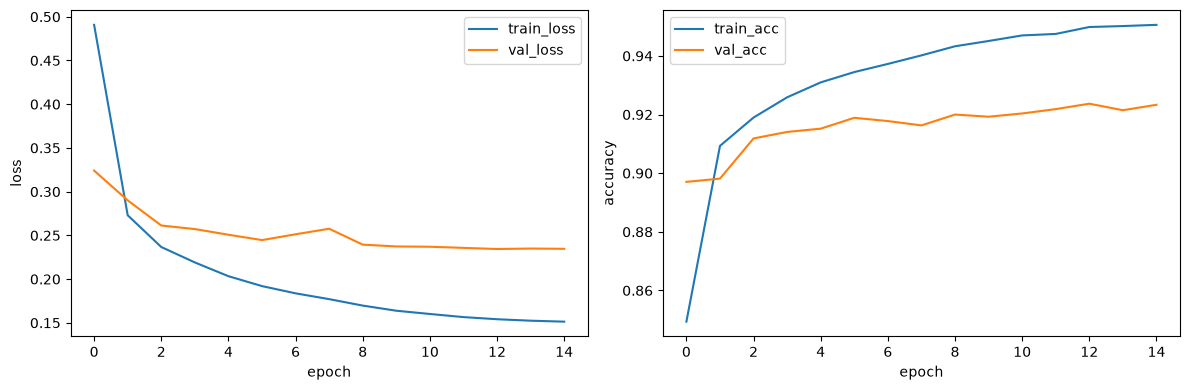

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
metrics_frozen[["train_loss", "val_loss"]].plot(ax=axes[0], ylabel="loss")
metrics_frozen[["train_acc", "val_acc"]].plot(ax=axes[1], ylabel="accuracy")
plt.tight_layout()
plt.show()

The frozen backbone ResNet-18 model reaches almost the same accuracy as the previous CNN.

### Full fine-tuning
Let us now fine-tune all layers of the pre-trained ResNet-18. We now set a smaller initial learning rate, as the pre-trained weights presumably already sit near a good solution and a larger rate could potentially push them away.

In [26]:
torch.manual_seed(0)
model_ft = build_resnet18().to(device)

metrics_ft = fit(model_ft, train_dataloader_imagenet, val_dataloader_imagenet,
                 loss_fn, n_epochs = 15, lr = 1e-4, device = device,
                 ckpt_path = "../data/processed/eurosat_resnet18_finetuned_best.pt",
                 verbose = True)

 0:   lr 1.0e-04,   train 0.307/0.901,   validation 0.125 / 0.958
 1:   lr 9.9e-05,   train 0.080/0.974,   validation 0.127 / 0.960
 2:   lr 9.6e-05,   train 0.045/0.985,   validation 0.110 / 0.966
 3:   lr 9.0e-05,   train 0.026/0.992,   validation 0.107 / 0.970
 4:   lr 8.3e-05,   train 0.022/0.993,   validation 0.137 / 0.966
 5:   lr 7.5e-05,   train 0.018/0.994,   validation 0.115 / 0.972
 6:   lr 6.5e-05,   train 0.010/0.997,   validation 0.107 / 0.970
 7:   lr 5.5e-05,   train 0.007/0.998,   validation 0.114 / 0.969
 8:   lr 4.5e-05,   train 0.005/0.999,   validation 0.108 / 0.971
 9:   lr 3.5e-05,   train 0.004/0.999,   validation 0.121 / 0.967
10:   lr 2.5e-05,   train 0.005/0.999,   validation 0.112 / 0.970
11:   lr 1.7e-05,   train 0.002/0.999,   validation 0.107 / 0.969
12:   lr 9.5e-06,   train 0.001/1.000,   validation 0.108 / 0.968
13:   lr 4.3e-06,   train 0.002/1.000,   validation 0.110 / 0.970
14:   lr 1.1e-06,   train 0.001/1.000,   validation 0.107 / 0.971


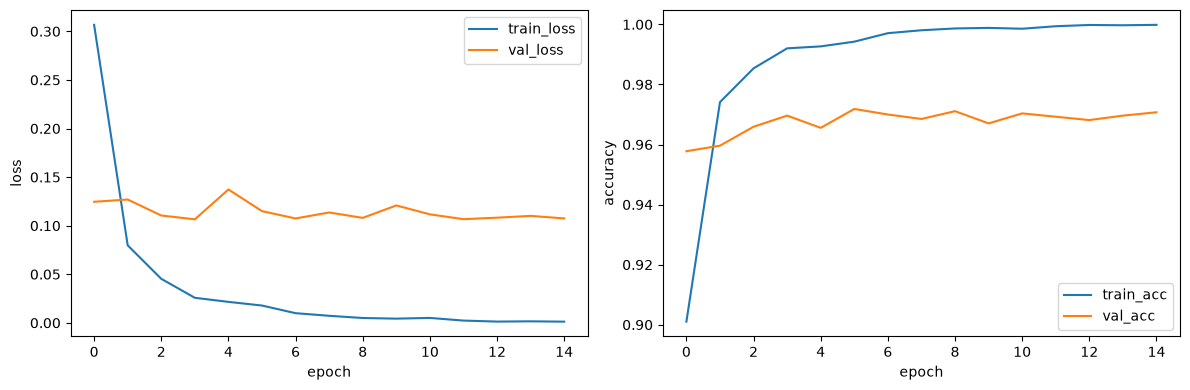

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
metrics_ft[["train_loss", "val_loss"]].plot(ax=axes[0], ylabel="loss")
metrics_ft[["train_acc", "val_acc"]].plot(ax=axes[1], ylabel="accuracy")
plt.tight_layout()
plt.show()

### Comparison between the three models


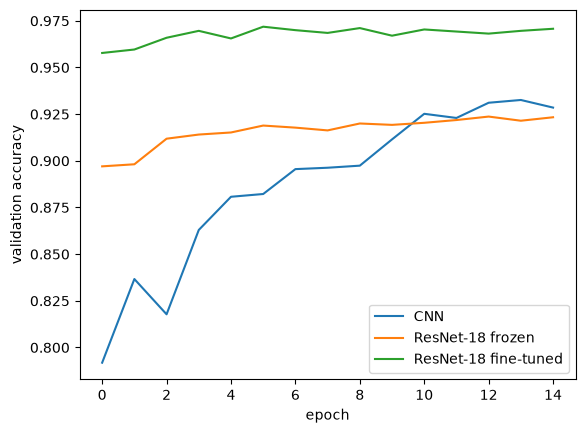

In [28]:
metrics_cos.val_acc.plot(label = "CNN")
metrics_frozen.val_acc.plot(label = "ResNet-18 frozen")
metrics_ft.val_acc.plot(label = "ResNet-18 fine-tuned")
plt.xlabel("epoch")
plt.ylabel("validation accuracy")
plt.legend()
plt.show()

In [29]:
# Rebuild each architecture and load its best checkpoint
cnn = CNN().to(device)
cnn.load_state_dict(torch.load("../data/processed/eurosat_cnn_best.pt", weights_only=True))

frozen = FrozenBackbone(build_resnet18()).to(device)
frozen.load_state_dict(torch.load("../data/processed/eurosat_resnet18_frozen_best.pt", weights_only=True))

finetuned = build_resnet18().to(device)
finetuned.load_state_dict(torch.load("../data/processed/eurosat_resnet18_finetuned_best.pt", weights_only=True))


def test_summary(name, model, test_loader, metrics):
    test_loss, test_acc = evaluate(model, test_loader, loss_fn, device)
    ci = 1.96 * np.sqrt(test_acc * (1 - test_acc) / len(test_loader.dataset))
    return {"model": name,
            "trainable_params": sum(p.numel() for p in model.parameters() if p.requires_grad),
            "best_val_acc": metrics["val_acc"].max(),
            "test_acc": test_acc,
            "test_ci95": ci,
            "sec_per_epoch": metrics["seconds"].mean()}


comparison = pd.DataFrame([
    test_summary("CNN", cnn, test_dataloader, metrics_cos),
    test_summary("ResNet-18 frozen", frozen, test_dataloader_imagenet, metrics_frozen),
    test_summary("ResNet-18 fine-tuned", finetuned, test_dataloader_imagenet, metrics_ft),
]).set_index("model").round(3)
comparison


,trainable_params,best_val_acc,test_acc,test_ci95,sec_per_epoch
model,,,,,
CNN,175402,0.933,0.943,0.009,15.491
ResNet-18 frozen,5130,0.924,0.920,0.010,16.534
ResNet-18 fine-tuned,11181642,0.972,0.971,0.006,17.315


Fine-tuning the pre-trained ResNet-18 yields the best test accuracy, beating all other models' final results even after a single epoch. Running on a GPU, no substantial change in the time spent per epoch is observed among models.